# Chart construction for waypoint Atlas-DeePC: seven methods, 100 seeds

This notebook replaces the old clustering study. Its filename retains `500` for existing links, but **this experiment uses 100 exploratory seeds, 211–310**. The previous notebook is preserved at `archive/notebooks/ablation_clustering_methods_500_before_20260916.ipynb`.

The baseline is the waypoint method in `notebooks/baselines/baseline_graph_routed_atlas_deepc.ipynb`: **Clarabel, λg=0.05, 48 charts, rank-60 uncentered linear behavioral bases, iterative N=10 terminal references, and graph waypoints**. Q/R, constraints, initialization, horizon, and all 320 control steps are unchanged. Every method uses the same immutable 144×37,800 Hankel matrix, retaining every column in its original order. There is no data recollection, filtering, added noise, fitted dynamics, rescue, expert data, nonlinear decoder, or early termination.

The gate inputs are the six periodic joint-configuration channels of the latest past output, standardized by the baseline mean/std. The four input-history channels have zero weight. Controller bases are constructed only from original full input-output columns. Cluster/embedding dimensions below are unrelated to controller rank 60.

## Fixed choices made before evaluation

| Method | Offline construction | Online assignment |
|---|---|---|
| Baseline K-means | Original MiniBatchKMeans settings: 48 clusters, seed11, 5 initializations, batch2048, max300, reassignment .002; refit checked against original atlas | Original nearest-centroid rule |
| Affine K-subspaces | 48 affine 2-planes, K-means initialization, at most50 assignment/PCA iterations | Minimum affine residual |
| Mixture of PPCA | 48 components, latent rank2, exact weighted-covariance PPCA M-step, EM max100, tolerance1e-5, isotropic noise floor1e-5 | Hard maximum posterior |
| Spectral | Sparse symmetric 20-neighbor RBF graph, bandwidth=median twentieth-neighbor distance, top48 normalized-adjacency eigenvectors, row normalization and K-means | Nyström eigenfunction extension and the same embedding K-means |
| Diffusion maps | Same sparse kernel, density normalization α=1, four nonconstant diffusion coordinates at time1 and K-means | Nyström diffusion coordinates and embedding K-means |
| Isomap | sklearn Isomap, 20 neighbors, four dimensions, ARPACK, graph shortest paths, then K-means | Native `Isomap.transform` and embedding K-means |
| UMAP | umap-learn, 20 neighbors, four dimensions, min_dist .1, 200 epochs, fit/transform seed11, then K-means | Native `UMAP.transform` per point and embedding K-means |

The four expensive graph/embedding methods share **1,500 uniformly sampled offline landmark indices, seed1701**. All original columns are assigned using the fitted extension; controller data are never reduced to landmarks. Exact fitted landmarks use their saved in-sample coordinates. UMAP transformation is deliberately called per point both offline and online, so its random-seeded transformation does not change with batch composition. Embedding K-means has 10 initializations, seed11, max300. Spectral/diffusion eigensolvers use a fixed starting vector and deterministic eigenvector signs.

Every method rebuilds medoids and within-episode directed transition counts. Medoids are actual members nearest the chart center in the baseline standardized physical features (original gate centroids for K-means, member means otherwise); medoid joint velocities are zeroed. Routing edge cost remains baseline feature RMS distance divided by square-root transition count, threshold3. Nonlinear embedding distance is never used for routing. Empty charts, supports below61, behavioral numerical rank below60, disconnected graphs, fitting nonconvergence, and runtime errors are explicitly reported. There is no chart repair, rank reduction, artificial graph bridge, or replacement controller. An unreachable terminal chart retains the original exception; unsolved QPs retain the original zero-action behavior.

## Timing, artifacts, and interpretation

All seven methods receive fresh rollouts, one worker and one numerical thread, rotating method order within each seed. Offline fit/atlas and behavioral-cache construction are separate. The recorded fit/atlas timer includes full-column assignments and initial model/parameter writes for the alternatives; it is not pure optimizer time. Baseline fitting also includes the reproduction check, while its first model writes occur outside that timer. Numerical-rank diagnostics and later artifact writes are outside both reported offline timers. UMAP's first fit includes compilation overhead. Each method receives a discarded 10-step seed210 warmup. All 320 per-step timers are saved; summaries omit the first5 steps per rollout. Chart-localization time includes the method's out-of-sample extension. QP time includes problem construction and solving. Measurements are wall-clock times on a shared computer.

Each method folder saves original-column memberships, preprocessing, fitted gate/model and coordinates, landmark indices, medoids, transition graph, all 48 behavioral bases/singular values/bounds/ranks, provenance/hashes, full rollouts and timings. Atlases reload without reclustering. Failure artifacts are retained. Baseline outcomes are recomputed; historical timing is not reused.

Strict success requires BOTH final30 and final100 windows to have mean error <10 mm and maximum <20 mm. The seed panel has been used for earlier studies and is **exploratory**, not untouched validation. No hyperparameters are selected by its results. Paired tests below are descriptive and unadjusted for six comparisons.

Primary references: [mixtures of PPCA, Tipping & Bishop](https://www.miketipping.com/papers/met-mppca.pdf), [diffusion maps, Coifman & Lafon](https://doi.org/10.1016/j.acha.2006.04.006), [spectral clustering](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.SpectralClustering.html), [Isomap and its transform](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.Isomap.html), [UMAP out-of-sample transform](https://umap-learn.readthedocs.io/en/latest/transform.html). Installed package versions are recorded below; spectral/diffusion and PPCA use explicit mathematical implementations backed by SciPy linear algebra.


In [1]:
RUN_EXPERIMENTS = False
from pathlib import Path
import json, sys
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from IPython.display import display
ROOT = next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/clustering_methods_experiment.py').exists())
sys.path.insert(0,str(ROOT/'src'))
import clustering_methods_experiment as experiment
R = experiment.RESULT
summary = json.loads((R/'summary.json').read_text())
assert summary['complete'], 'Experiment is still running; no final report yet.'
assert summary['signature'] == experiment.signature()
assert summary['signature']['seeds'] == list(range(211,311))
assert summary['data_hash_final'] == summary['signature']['data_sha256']
METHODS = experiment.METHODS
order = list(METHODS)
panels = summary['panels']
frames = {}
for method,panel in panels.items():
    checked = [experiment.validate(R/method/f"seed{r['seed']}.npz",method,r['seed'],summary['signature']) for r in panel['results']]
    assert checked == panel['results']
    meta = panel['offline']
    assert meta['data_sha256'] == summary['data_hash_final']
    for name,digest in meta['files'].items():
        assert experiment.file_digest(R/method/name) == digest
    if checked:
        frames[method]=pd.DataFrame(checked).set_index('seed').sort_index()
if 'kmeans' in frames:
    for method,frame in frames.items():
        common=frames['kmeans'].index.intersection(frame.index)
        np.testing.assert_array_equal(frames['kmeans'].loc[common].exact_target_xy.tolist(),frame.loc[common].exact_target_xy.tolist())
F=R/'figures'; F.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi':125,'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
colors=dict(zip(order,plt.get_cmap('tab10').colors[:7]))
def save(name):
    plt.tight_layout()
    plt.savefig(F/(name+'.png'),bbox_inches='tight')
    plt.show()
display(pd.Series(summary['signature']['versions'],name='Installed version'))
print('Dataset SHA-256:',summary['data_hash_final'])
print('Validated full rollouts:',summary['rollouts'],'/700')


numpy                1.26.4
scipy                1.13.1
scikit-learn          1.7.2
cvxpy                 1.6.5
clarabel             0.11.1
gymnasium             1.2.3
mujoco               3.12.0
umap-learn      0.5.9.post2
pynndescent          0.5.13
numba                0.66.0
joblib                1.5.3
Name: Installed version, dtype: object

Dataset SHA-256: 75c6e2e8376c00ac1fc032ecaaa31b9a3eb830b671f68a18e559b22f9263c45b
Validated full rollouts: 700 /700


## Success and final-100 tracking error

,label,completed,successes,success_pct,CI_low,CI_high,median_error_mm,P90_error_mm,unsolved_QPs,trial_errors
method,,,,,,,,,,
kmeans,Baseline K-means,100,93,93.0,86.250,96.568,2.062,5.426,0,0
kflats,Affine K-subspaces,100,87,87.0,79.020,92.243,2.140,15.651,0,0
mppca,Mixture of PPCA,100,88,88.0,80.188,93.001,2.432,12.450,0,0
spectral,Spectral clustering,100,90,90.0,82.563,94.477,2.063,8.997,0,0
diffusion,Diffusion maps + K-means,100,77,77.0,67.846,84.157,2.568,336.675,0,0
isomap,Isomap + K-means,100,67,67.0,57.305,75.437,2.826,269.531,0,0
umap,UMAP + K-means,100,92,92.0,85.002,95.891,2.089,5.571,0,0


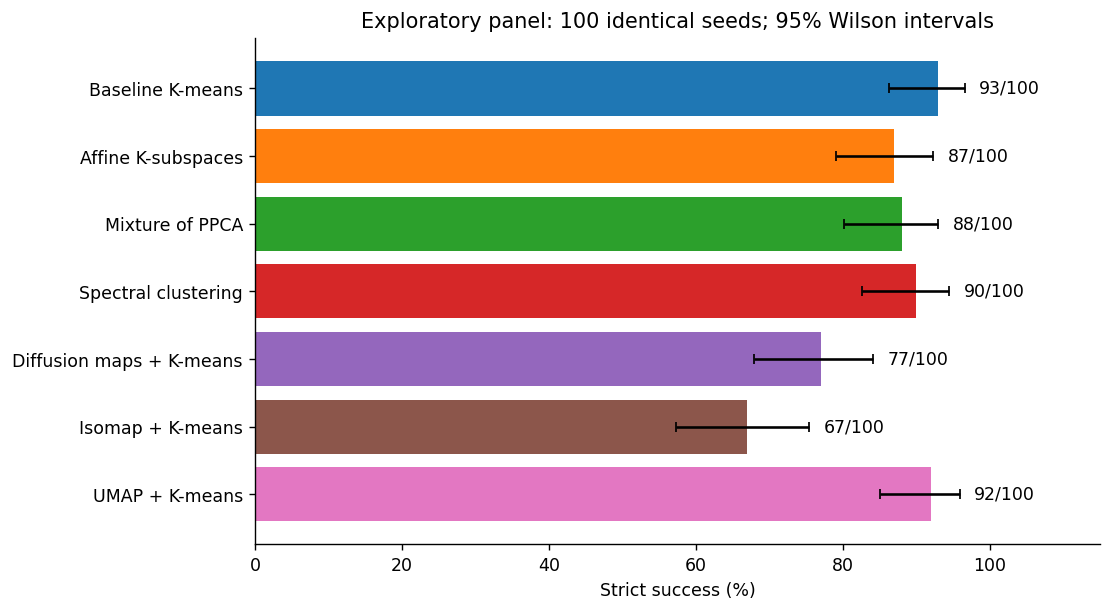

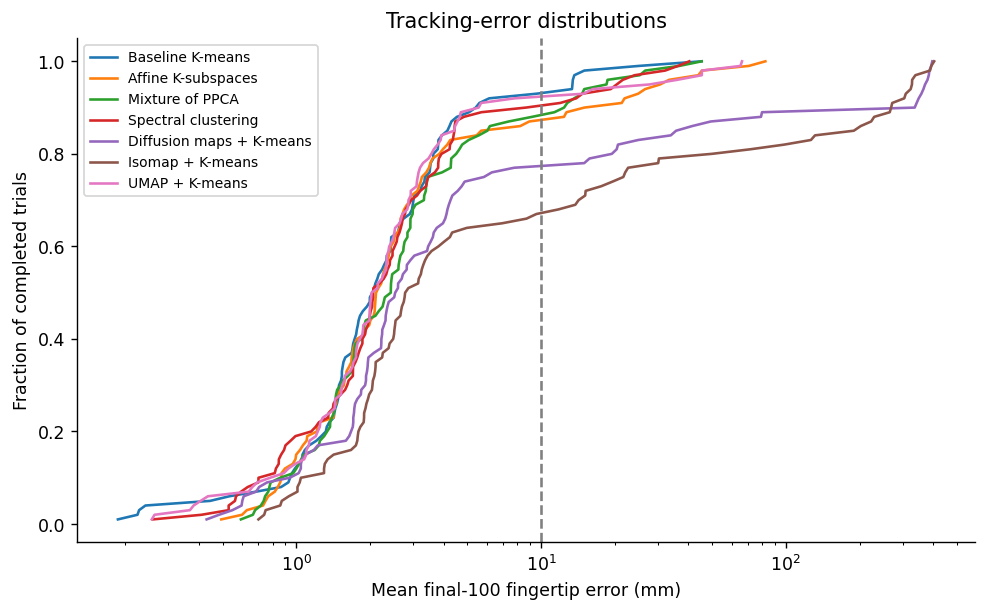

In [2]:
def wilson(k,n):
    z=1.959963984540054; p=k/n; den=1+z*z/n
    center=(p+z*z/(2*n))/den
    half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
    return 100*(center-half),100*(center+half)
records=[]
for method in order:
    p=panels.get(method)
    if p and len(p['results']):
        frame=frames[method]; k=p['successes']; n=len(frame)
        low,high=wilson(k,n)
        records.append({'method':method,'label':METHODS[method]['label'],'completed':n,'successes':k,
            'success_pct':100*k/n if n==100 else np.nan,'CI_low':low,'CI_high':high,
            'median_error_mm':1000*frame.mean_last_100.median(),'P90_error_mm':1000*frame.mean_last_100.quantile(.9),
            'unsolved_QPs':int(frame.unsolved_steps.sum()),'trial_errors':len(p['trial_failures'])})
    else:
        records.append({'method':method,'label':METHODS[method]['label'],'completed':0,'successes':0,
            'success_pct':np.nan,'CI_low':np.nan,'CI_high':np.nan})
table=pd.DataFrame(records).set_index('method')
display(table.round(3))
for method,failure in summary['offline_failures'].items():
    print('OFFLINE FAILURE:',method,failure['error'])
for method,p in panels.items():
    if p['trial_failures']: display(pd.DataFrame(p['trial_failures'])[['seed','error']].assign(method=method))
fig,ax=plt.subplots(figsize=(9,5))
for i,m in enumerate(order):
    row=table.loc[m];rate=row.success_pct
    if pd.notna(rate):
        ax.barh(i,rate,color=colors[m])
        ax.errorbar(rate,i,xerr=[[rate-row.CI_low],[row.CI_high-rate]],fmt='none',color='black',capsize=3)
        ax.text(row.CI_high+2,i,f"{int(row.successes)}/100",va='center')
    else: ax.text(1,i,f"Incomplete: {int(row.completed)}/100 trials",va='center')
ax.set(yticks=range(7),yticklabels=[METHODS[m]['label'] for m in order],xlim=(0,115),xlabel='Strict success (%)',title='Exploratory panel: 100 identical seeds; 95% Wilson intervals')
ax.invert_yaxis();save('success')
fig,ax=plt.subplots(figsize=(8,5))
for m,frame in frames.items():
    ax.plot(np.sort(1000*frame.mean_last_100),np.arange(1,len(frame)+1)/len(frame),label=METHODS[m]['label'],color=colors[m])
ax.axvline(10,color='gray',linestyle='--');ax.set(xscale='log',xlabel='Mean final-100 fingertip error (mm)',ylabel='Fraction of completed trials',title='Tracking-error distributions')
ax.legend(fontsize=8);save('error_distributions')


## Paired comparisons against K-means

,method,paired_seeds,baseline_only,alternative_only,both_success,both_failure,median_paired_error_change_mm,McNemar_exact_unadjusted_p
0,kflats,100,10,4,83,3,0.0216,0.1796
1,mppca,100,9,4,84,3,-0.0561,0.2668
2,spectral,100,6,3,87,4,-0.0621,0.5078
3,diffusion,100,21,5,72,2,0.2658,0.0025
4,isomap,100,30,4,63,3,0.1948,0.0000
5,umap,100,4,3,89,4,0.0373,1.0000


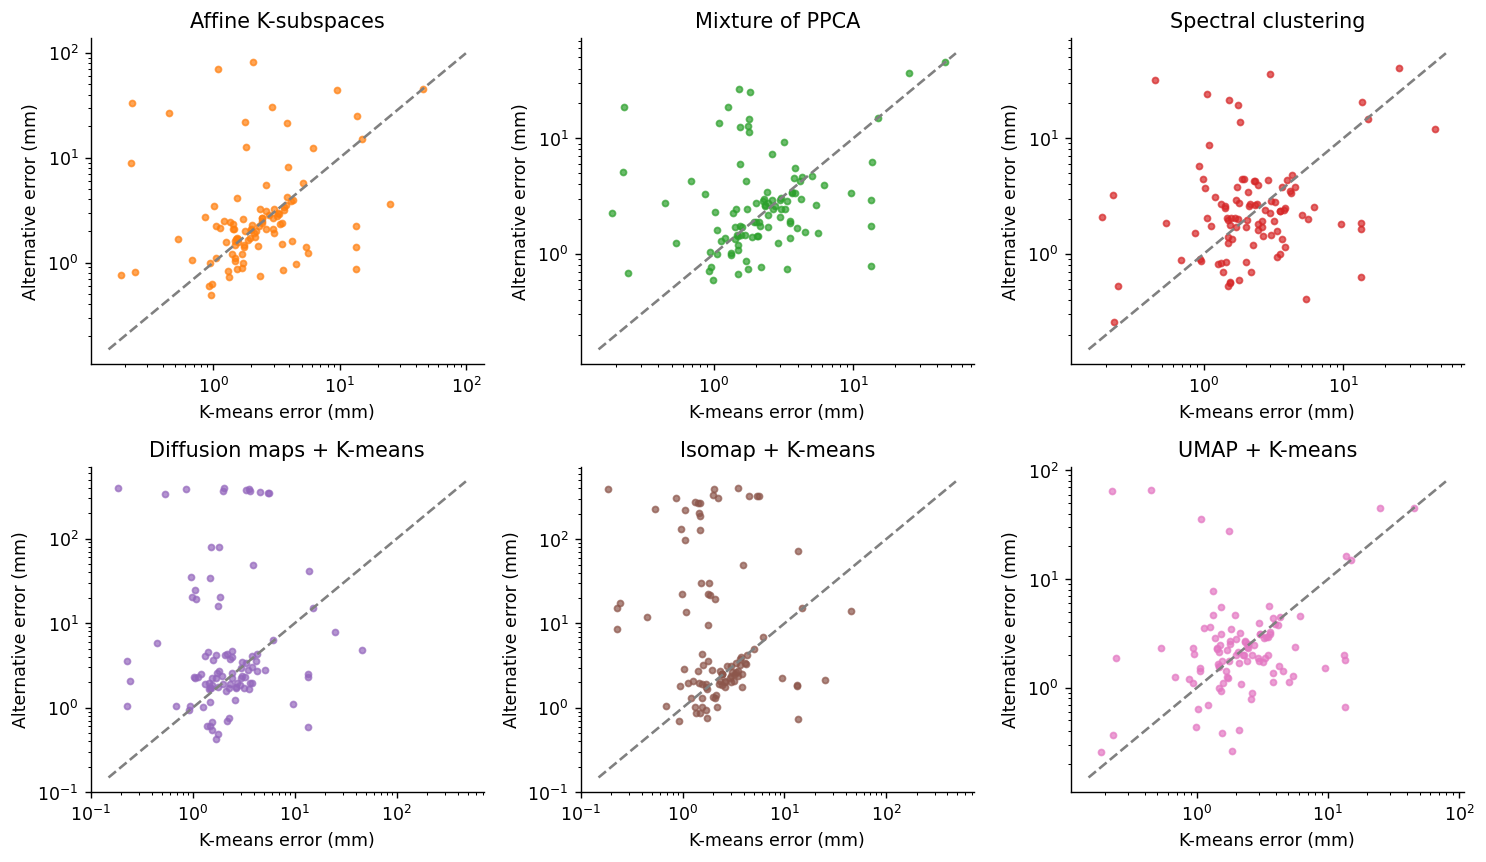

In [3]:
paired=[]
base=frames.get('kmeans')
fig,axes=plt.subplots(2,3,figsize=(12,7))
for ax,m in zip(axes.flat,order[1:]):
    ax.set_title(METHODS[m]['label'])
    if base is None or m not in frames:
        ax.text(.5,.5,'Method unavailable',ha='center');continue
    f=frames[m];common=base.index.intersection(f.index)
    a=base.loc[common];b=f.loc[common]
    sa=a.success_30 & a.success_100;sb=b.success_30 & b.success_100
    only_a=int((sa & ~sb).sum());only_b=int((~sa & sb).sum());discordant=only_a+only_b
    paired.append({'method':m,'paired_seeds':len(common),'baseline_only':only_a,'alternative_only':only_b,
        'both_success':int((sa&sb).sum()),'both_failure':int((~sa&~sb).sum()),
        'median_paired_error_change_mm':float(1000*(b.mean_last_100-a.mean_last_100).median()),
        'McNemar_exact_unadjusted_p':float(binomtest(only_b,discordant).pvalue) if discordant else 1.0})
    x=1000*a.mean_last_100;y=1000*b.mean_last_100
    ax.scatter(x,y,s=12,alpha=.7,color=colors[m]);lo=max(min(x.min(),y.min())*.8,1e-5);hi=max(x.max(),y.max())*1.2
    ax.plot([lo,hi],[lo,hi],color='gray',linestyle='--');ax.set(xscale='log',yscale='log',xlabel='K-means error (mm)',ylabel='Alternative error (mm)')
display(pd.DataFrame(paired).round(4));save('paired_errors')


## Computation, chart health, and solver outcomes

mean_ms                                      \
method                       diffusion   isomap   kflats   kmeans    mppca   
module                                                                       
Chart localization              0.8381   1.9469   0.0712   0.0712   0.0705   
Graph routing                   0.0095   0.0120   0.0066   0.0066   0.0079   
Linear subspace retrieval       0.0009   0.0010   0.0009   0.0008   0.0010   
Other control-loop work         0.0396   0.0369   0.0371   0.0352   0.0373   
QP construction and solve      37.5407  37.3314  37.2184  36.3605  37.8438   
Terminal-reference selection    0.0184   0.0197   0.0168   0.0164   0.0181   
Total online control           38.4472  39.3479  37.3508  36.4907  37.9786   

                                               median_ms                    \
method                       spectral     umap diffusion   isomap   kflats   
module                                                                       
Chart localization             0.8449   2.8441    0.7413   1.7580   0.0640   
Graph routing                  0.0084   0.0102    0.0073   0.0103   0.0055   
Linear subspace retrieval      0.0009   0.0009    0.0008   0.0008   0.0008   
Other control-loop work        0.0351   0.0352    0.0303   0.0314   0.0315   
QP construction and solve     36.5657  36.8268   34.0181  34.3756  33.5162   
Terminal-reference selection   0.0182   0.0198    0.0161   0.0171   0.0148   
Total online control          37.4732  39.7370   34.8642  36.2514  33.6396   

                              ...                               p99_ms  \
method                        ...    mppca spectral     umap diffusion   
module                        ...                                        
Chart localization            ...   0.0624   0.7590   2.5445    2.2662   
Graph routing                 ...   0.0055   0.0070   0.0085    0.0358   
Linear subspace retrieval     ...   0.0008   0.0008   0.0008    0.0015   
Other control-loop work       ...   0.0317   0.0307   0.0305    0.1331   
QP construction and solve     ...  33.6145  33.6970  33.2555  102.4656   
Terminal-reference selection  ...   0.0158   0.0163   0.0158    0.0626   
Total online control          ...  33.7401  34.5583  35.9077  103.9653   

                                                                      \
method                          isomap    kflats    kmeans     mppca   
module                                                                 
Chart localization              4.4541    0.2383    0.2223    0.2302   
Graph routing                   0.0418    0.0220    0.0205    0.0245   
Linear subspace retrieval       0.0015    0.0023    0.0022    0.0027   
Other control-loop work         0.1174    0.1284    0.1145    0.1390   
QP construction and solve     100.7908  117.1866  104.6788  118.0367   
Terminal-reference selection    0.0628    0.0619    0.0570    0.0660   
Total online control          103.6025  117.6520  104.8332  118.2292   

                                                  
method                        spectral      umap  
module                                            
Chart localization              1.9917    6.3042  
Graph routing                   0.0307    0.0366  
Linear subspace retrieval       0.0015    0.0017  
Other control-loop work         0.1130    0.1168  
QP construction and solve      99.2443   99.8270  
Terminal-reference selection    0.0623    0.0583  
Total online control          100.6306  104.9661  

[7 rows x 21 columns]

,fit_and_atlas_s,basis_cache_s,min_chart_size,max_chart_size,min_behavioral_numerical_rank,controller_basis_rank,weak_components,strong_components,directed_edges,gate_converged
method,,,,,,,,,,
kmeans,0.1578,0.1611,558,1292,144,60,1,1,298,not applicable
kflats,11.4704,0.1224,520,1293,144,60,1,1,290,False
mppca,13.0481,0.1309,485,1088,144,60,1,1,289,False
spectral,1.1076,0.1525,466,1387,144,60,1,1,302,not applicable
diffusion,0.3943,0.1362,521,2122,144,60,1,1,303,not applicable
isomap,3.2921,0.1271,365,1928,144,60,1,1,298,not applicable
umap,102.0507,0.1239,423,1516,144,60,1,1,311,not applicable


,kmeans,kflats,mppca,spectral,diffusion,isomap,umap
Solver status,,,,,,,
optimal,32000,32000,32000,32000,32000,32000,32000


One-time terminal-candidate setup per rollout (ms), outside online loop:


,mean,median,p95
kmeans,16.4604,5.2355,9.0417
kflats,5.5565,5.0843,8.7828
mppca,5.6156,5.2775,7.9005
spectral,5.7893,5.1987,8.8252
diffusion,9.9242,5.1429,8.3799
isomap,8.1764,5.0609,18.2154
umap,5.8483,5.1087,9.1774


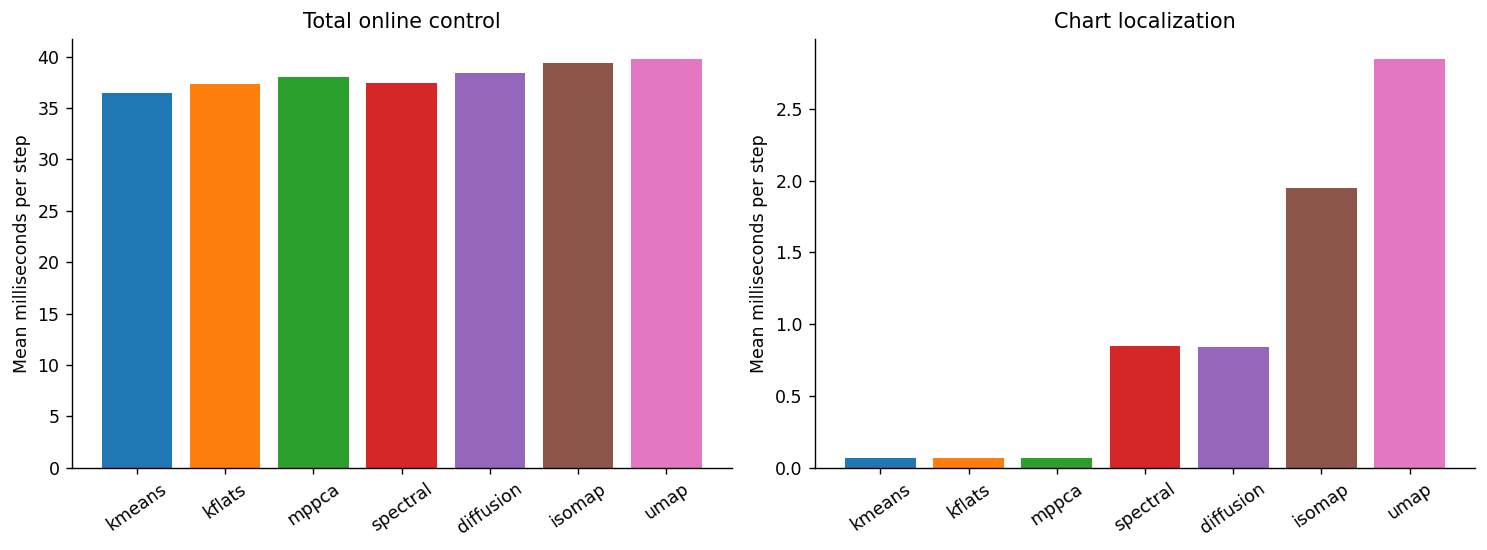

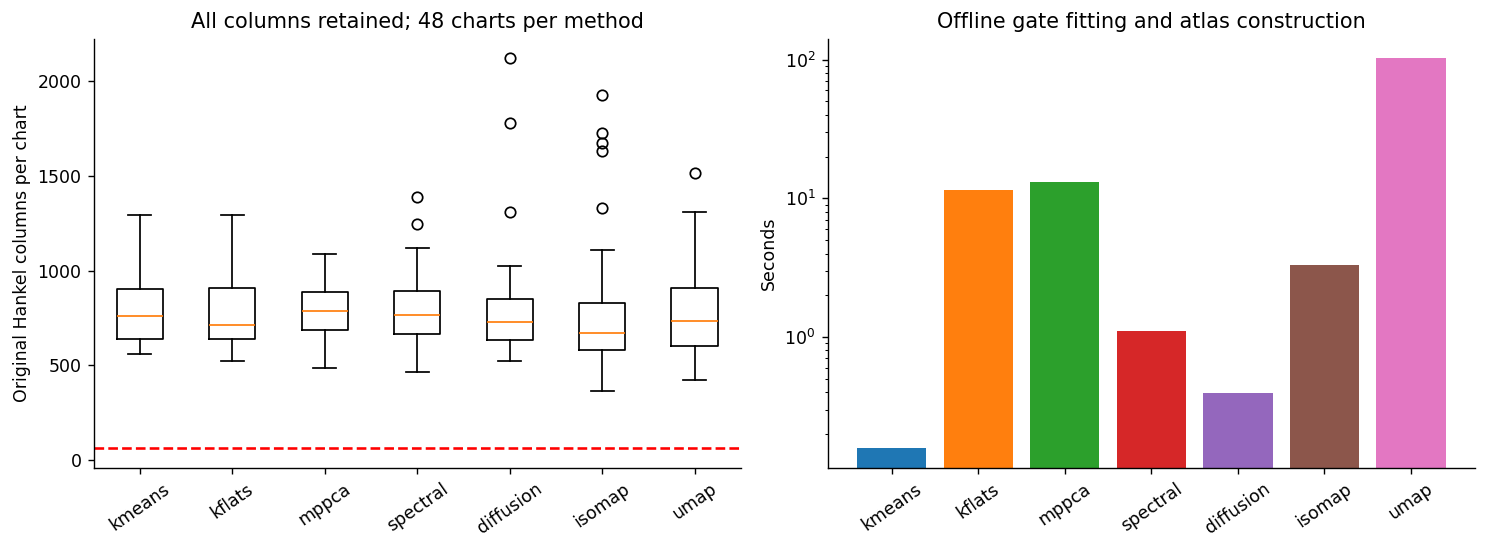

In [4]:
timing=[];offline=[];statuses={}
for m,p in panels.items():
    if p['timing']:
        assert p['timing']['timed_steps']==315*len(p['results'])
        timing += [{'method':m,**item} for item in p['timing']['modules']]
    meta=p['offline'];health=meta['health']
    offline.append({'method':m,'fit_and_atlas_s':meta['fit_and_atlas_seconds'],'basis_cache_s':meta['basis_cache_seconds'],
        'min_chart_size':min(health['chart_sizes']),'max_chart_size':max(health['chart_sizes']),
        'min_behavioral_numerical_rank':min(health['numerical_ranks']),'controller_basis_rank':60,
        'weak_components':health['weak_components'],'strong_components':health['strong_components'],
        'directed_edges':health['directed_edges'],'gate_converged':meta['gate_diagnostics'].get('converged','not applicable')})
    statuses[m]=dict(sum((Counter(r['statuses']) for r in p['results']),Counter()))
    assert sum(statuses[m].values())==320*len(p['results'])
timing=pd.DataFrame(timing)
display(timing.pivot(index='module',columns='method',values=['mean_ms','median_ms','p99_ms']).round(4))
display(pd.DataFrame(offline).set_index('method').round(4))
display(pd.DataFrame(statuses).fillna(0).astype(int).rename_axis('Solver status'))
print('One-time terminal-candidate setup per rollout (ms), outside online loop:')
display(pd.DataFrame({m:p['timing']['one_time_goal_setup_ms'] for m,p in panels.items() if p['timing']}).T.round(4))
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for ax,module in zip(axes,['Total online control','Chart localization']):
    t=timing[timing.module==module].set_index('method')
    names=[m for m in order if m in t.index]
    ax.bar(range(len(names)),t.loc[names].mean_ms,color=[colors[m] for m in names])
    ax.set(xticks=range(len(names)),xticklabels=names,ylabel='Mean milliseconds per step',title=module)
    ax.tick_params(axis='x',rotation=35)
save('online_timing')
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
names=[m for m in order if m in panels]
axes[0].boxplot([panels[m]['offline']['health']['chart_sizes'] for m in names],tick_labels=names)
axes[0].axhline(61,color='red',linestyle='--');axes[0].set(ylabel='Original Hankel columns per chart',title='All columns retained; 48 charts per method')
axes[1].bar(names,[panels[m]['offline']['fit_and_atlas_seconds'] for m in names],color=[colors[m] for m in names])
axes[1].set(ylabel='Seconds',title='Offline gate fitting and atlas construction',yscale='log')
for ax in axes: ax.tick_params(axis='x',rotation=35)
save('offline_diagnostics')


## Representative arm-configuration clouds

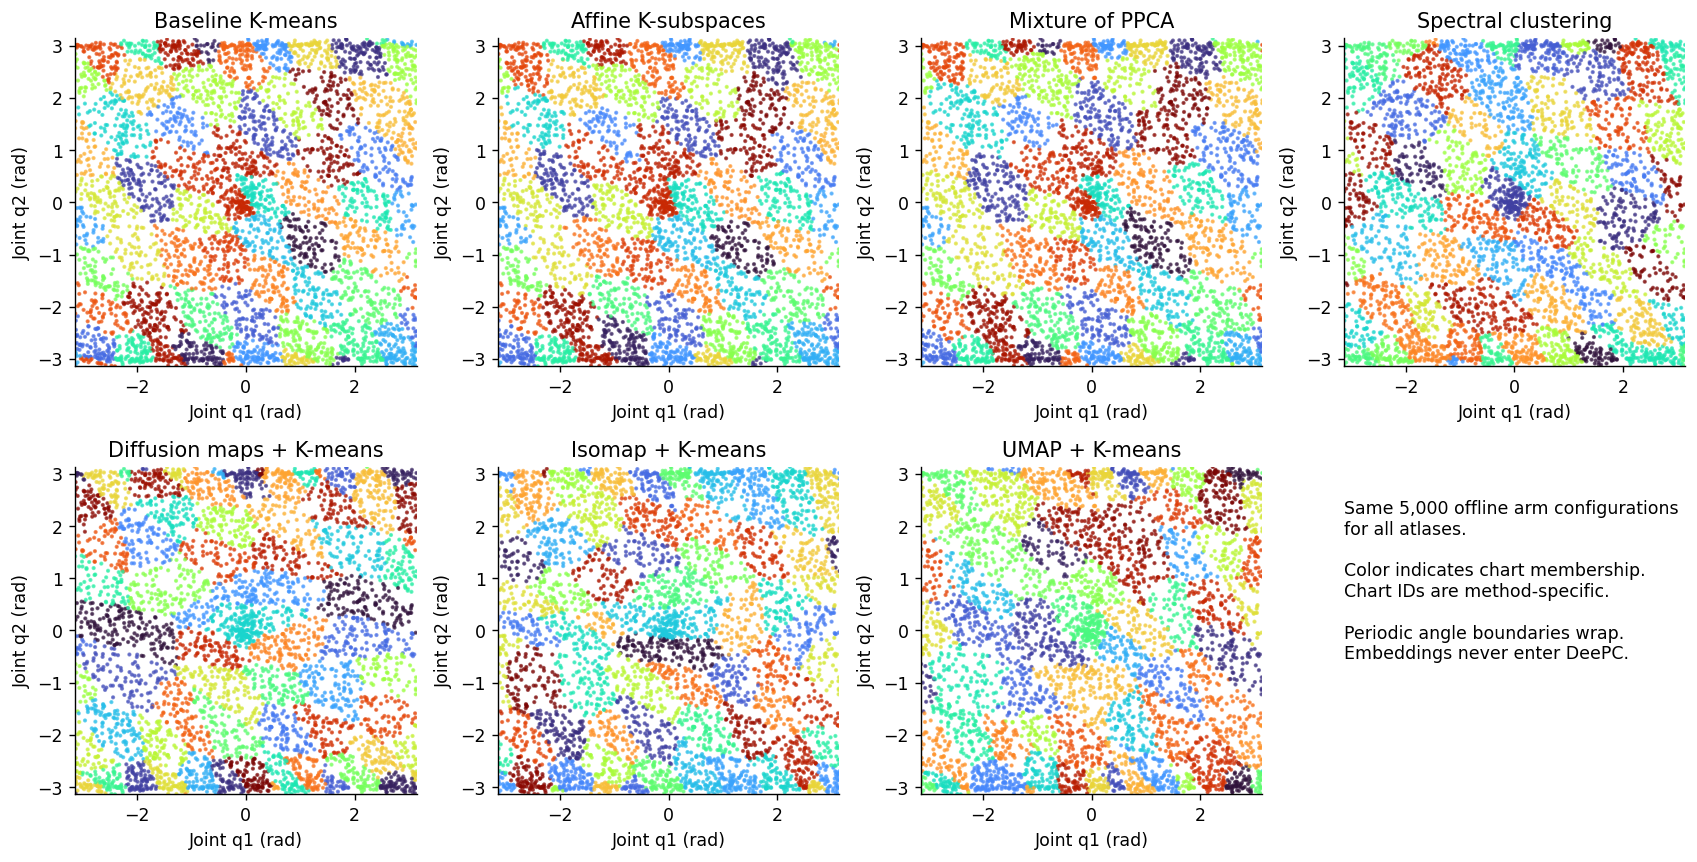

Report saved. Interpret this as an exploratory comparison with fixed pre-evaluation settings.


In [5]:
H=np.load(experiment.DATA,mmap_mode='r')
Y=H[experiment.routed.pipe.M*experiment.routed.pipe.L:].reshape(experiment.routed.pipe.L,10,H.shape[1])[experiment.routed.pipe.T_INI-1].T
sample=np.sort(np.random.default_rng(1702).choice(len(Y),5000,replace=False))
q1=np.arctan2(Y[sample,2],Y[sample,0]);q2=np.arctan2(Y[sample,3],Y[sample,1])
fig,axes=plt.subplots(2,4,figsize=(14,7))
for ax,m in zip(axes.flat,order):
    path=R/m/'memberships.npz'
    ax.set_title(METHODS[m]['label'])
    if path.exists():
        with np.load(path) as a:
            np.testing.assert_array_equal(a['column_indices'],np.arange(H.shape[1]))
            labels=a['labels'];assert len(labels)==H.shape[1]
        ax.scatter(q1,q2,c=labels[sample],cmap='turbo',vmin=0,vmax=47,s=2,alpha=.65,rasterized=True)
    else: ax.text(.5,.5,'Fitting failed',transform=ax.transAxes,ha='center')
    ax.set(xlim=(-np.pi,np.pi),ylim=(-np.pi,np.pi),xlabel='Joint q1 (rad)',ylabel='Joint q2 (rad)')
axes.flat[-1].axis('off')
axes.flat[-1].text(0,.9,'Same 5,000 offline arm configurations\nfor all atlases.\n\nColor indicates chart membership.\nChart IDs are method-specific.\n\nPeriodic angle boundaries wrap.\nEmbeddings never enter DeePC.',va='top')
save('arm_configuration_clouds')
report={'complete':True,'rollouts':summary['rollouts'],'all_methods_succeeded':summary['all_methods_succeeded'],
    'outcomes':table.reset_index().where(pd.notna(table.reset_index()),None).to_dict(orient='records'),
    'paired':paired,'timing':timing.to_dict(orient='records'),'offline':offline,'statuses':statuses,
    'offline_failures':summary['offline_failures'],'dataset_sha256':summary['data_hash_final'],
    'figures':[str(p) for p in sorted(F.glob('*.png'))]}
(R/'notebook_report.json').write_text(json.dumps(report,indent=2))
print('Report saved. Interpret this as an exploratory comparison with fixed pre-evaluation settings.')


## Observed comparison and limits

| Method | Success | Median error (mm) | Mean / median / P99 time (ms) |
|---|---:|---:|---:|
| kmeans | 93/100 | 2.062 | 36.49 / 33.12 / 104.83 |
| kflats | 87/100 | 2.140 | 37.35 / 33.64 / 117.65 |
| mppca | 88/100 | 2.432 | 37.98 / 33.74 / 118.23 |
| spectral | 90/100 | 2.063 | 37.47 / 34.56 / 100.63 |
| diffusion | 77/100 | 2.568 | 38.45 / 34.86 / 103.97 |
| isomap | 67/100 | 2.826 | 39.35 / 36.25 / 103.60 |
| umap | 92/100 | 2.089 | 39.74 / 35.91 / 104.97 |

K-means has the highest observed success rate and lowest mean/median online time in this fixed comparison. UMAP is closest in success (92 versus93), but its native online extension increases localization cost. In the paired panel, K-means alone succeeds on4 cases and UMAP alone on3, so these100 exploratory cases do not establish a reliable success advantage over UMAP. Spectral is next at90 successes. Diffusion and Isomap have substantially more unsuccessful rollouts under the fixed landmark/embedding settings; this does not establish that those algorithm families are universally inferior.

All224,000 QPs are optimal. Every atlas has48 nonempty charts, at least365 original columns per chart, full numerical behavioral rank144 before truncation, rank60 controller bases, and a strongly connected directed transition graph. Thus the observed failures are not explained by unsolved QPs, empty charts, or disconnected routing graphs. Mechanistic explanations would require a separate diagnostic study.

K-subspaces and MPPCA reached50 and100 iterations without meeting their stopping criteria, respectively. Their reported results describe those capped fits. Spectral, diffusion, Isomap and UMAP use1,500-landmark approximations with all37,800 original columns reassigned. No settings were retuned against evaluation results. The 100 seeds are exploratory, six paired tests are unadjusted, and wall-clock timing can reflect shared-computer load. Offline fit/atlas preparation includes the overheads described above.

The fresh K-means distance traces reproduce the original rank60 study bit-for-bit for all100 seeds (see `baseline_reproduction.json`); historical timing is never substituted for this run's measurements.
